# CivicAI - 01 Data cleaning and EDA

This notebook has two parts:

1. **Target and threshold** (Phase 2) - build the thing we want to predict and check that the 7-day threshold is a sensible choice.
2. **Cleaning and EDA** (Phase 3) - added below this section later.

# 1. Target and threshold

**Goal of this section.** The model will predict `resolved_within_7d`: 1 if a request was closed within 7 days of being created, otherwise 0. Before any modeling we check:

- how long requests really take to close,
- how balanced the two classes are at 7 days and at other possible thresholds,
- whether our 199,580-row sample looks like the full NYC 311 table.

**Rule we follow.** Everything about the threshold is measured on the *training period* only (the oldest 70% of requests). Looking at newer rows to pick the threshold would leak information from the validation and test data.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

RAW_FILE = Path("../data/raw/nyc311_raw.parquet")
FIG_DIR = Path("../reports/figures")
FIG_DIR.mkdir(parents=True, exist_ok=True)

THRESHOLD_DAYS = 7                      # the project's target threshold
CANDIDATE_DAYS = [1, 2, 3, 5, 7, 14]    # thresholds we compare
TRAIN_SHARE = 0.70                      # oldest 70% = training period

# One simple chart style for the whole notebook
BLUE, GREY, INK = "#2a78d6", "#c3c2b7", "#52514e"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": GREY, "axes.labelcolor": INK,
    "xtick.color": INK, "ytick.color": INK,
    "axes.grid": True, "grid.color": "#e8e7e3", "axes.axisbelow": True,
})
print("pandas", pd.__version__)

pandas 2.3.3


## 1.1 Load the raw data and parse the dates

The raw file keeps every column as text, exactly as the API sent it. Here we turn `created_date` and `closed_date` into real datetimes. `errors="coerce"` turns any text that is not a valid date into a missing value, so we can count parsing failures instead of crashing.

In [2]:
raw = pd.read_parquet(RAW_FILE)
print(f"Raw rows: {len(raw):,}   columns: {raw.shape[1]}")

df = raw[["unique_key", "created_date", "closed_date", "complaint_type", "borough"]].copy()
for col in ["created_date", "closed_date"]:
    parsed = pd.to_datetime(df[col], errors="coerce")
    # A parsing failure = the raw text was there, but it did not become a date
    failures = (df[col].notna() & parsed.isna()).sum()
    print(f"{col}: {df[col].isna().sum():,} missing in raw, {failures:,} parsing failures")
    df[col] = parsed

Raw rows: 199,580   columns: 44
created_date: 0 missing in raw, 0 parsing failures


closed_date: 702 missing in raw, 0 parsing failures


## 1.2 Duration, and rows we cannot use

`duration_hours` = `closed_date` minus `created_date`, in hours.

- **Missing `closed_date`**: no duration can be computed, so no target. Dropped.
- **Negative duration**: closed before it was created, which is impossible, so it is a data error. Dropped.
- **Zero duration**: closed at the exact second it was created. Strange, but it is a valid "resolved within 7 days", so we **keep** these and look at them again in Phase 3.

The rows are dropped only inside this notebook. The raw file on disk is not changed.

In [3]:
df["duration_hours"] = (df["closed_date"] - df["created_date"]).dt.total_seconds() / 3600

n_missing = df["closed_date"].isna().sum()
n_negative = (df["duration_hours"] < 0).sum()
n_zero = (df["duration_hours"] == 0).sum()
print(f"Missing closed_date : {n_missing:,} ({n_missing / len(df):.2%})")
print(f"Negative duration   : {n_negative:,} ({n_negative / len(df):.2%})")
print(f"Zero duration       : {n_zero:,} ({n_zero / len(df):.2%})  (kept)")

work = df[df["duration_hours"].notna() & (df["duration_hours"] >= 0)].copy()
print(f"\nRows remaining after dropping missing and negative: {len(work):,} of {len(df):,}")

Missing closed_date : 702 (0.35%)
Negative duration   : 11 (0.01%)
Zero duration       : 3,458 (1.73%)  (kept)

Rows remaining after dropping missing and negative: 198,867 of 199,580


## 1.3 The training period

We sort by `created_date` and call the oldest 70% the training period. All threshold numbers below use only these rows.

(The final 70 / 15 / 15 split is made in Phase 4 on the cleaned data, so its cut-off date may move by a few hours. The idea is the same.)

In [4]:
work = work.sort_values("created_date").reset_index(drop=True)
n_train = int(len(work) * TRAIN_SHARE)
train = work.iloc[:n_train]
later = work.iloc[n_train:]
train_end = train["created_date"].max()

print(f"Training period : {len(train):,} rows, {train['created_date'].min()} to {train_end}")
print(f"Later rows      : {len(later):,} rows, {later['created_date'].min()} to {later['created_date'].max()}")

Training period : 139,206 rows, 2024-01-01 00:00:00 to 2025-12-02 20:45:49


Later rows      : 59,661 rows, 2025-12-02 20:48:18 to 2026-08-31 23:59:06


## 1.4 How long do requests take? (training period)

The table shows what share of training requests were closed within each candidate threshold. That share is the size of the positive class if we chose that threshold.

In [5]:
dur = train["duration_hours"]
shares = pd.DataFrame({
    "threshold_days": CANDIDATE_DAYS,
    "resolved_within": [(dur <= d * 24).mean() for d in CANDIDATE_DAYS],
})
shares["not_resolved_within"] = 1 - shares["resolved_within"]
shares["smaller_class"] = shares[["resolved_within", "not_resolved_within"]].min(axis=1)
display(shares.style.format({c: "{:.1%}" for c in shares.columns[1:]}).hide(axis="index"))

median_h, p75_h = dur.median(), dur.quantile(0.75)
print(f"Median duration         : {median_h:,.1f} hours = {median_h / 24:.2f} days")
print(f"75th percentile duration: {p75_h:,.1f} hours = {p75_h / 24:.2f} days")
print(f"Mean duration           : {dur.mean():,.1f} hours = {dur.mean() / 24:.2f} days")

threshold_days,resolved_within,not_resolved_within,smaller_class
1,61.6%,38.4%,38.4%
2,69.5%,30.5%,30.5%
3,74.6%,25.4%,25.4%
5,79.8%,20.2%,20.2%
7,82.8%,17.2%,17.2%
14,87.8%,12.2%,12.2%


Median duration         : 7.0 hours = 0.29 days
75th percentile duration: 74.0 hours = 3.08 days
Mean duration           : 286.6 hours = 11.94 days


**Histogram of duration.** Durations run from seconds to more than a year, so the x axis uses a log scale (each step is 10 times longer). Zero-duration rows cannot be drawn on a log axis, so they are left out of this chart only and counted in the title.

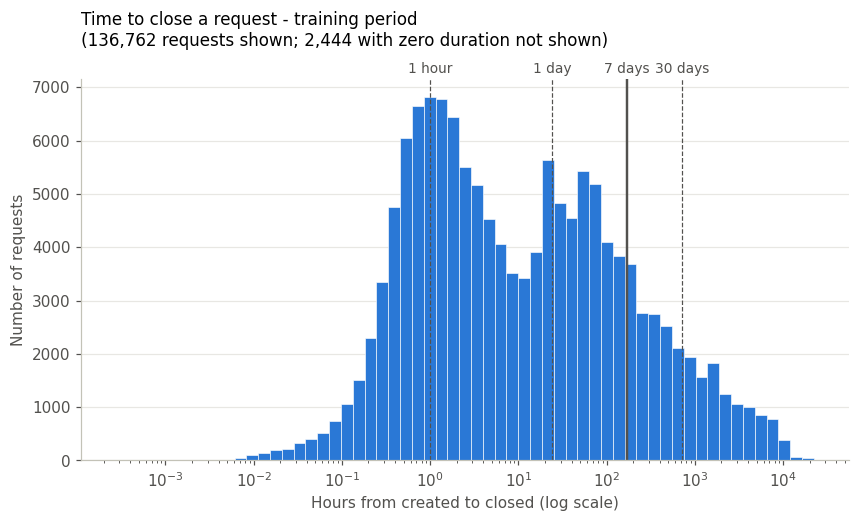

In [6]:
positive = dur[dur > 0]
bins = np.logspace(np.log10(positive.min()), np.log10(positive.max()), 60)

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.hist(positive, bins=bins, color=BLUE, edgecolor="white", linewidth=0.4)
ax.set_xscale("log")
for hours, label in [(1, "1 hour"), (24, "1 day"), (24 * 7, "7 days"), (24 * 30, "30 days")]:
    ax.axvline(hours, color=INK, linewidth=1.6 if hours == 168 else 0.8,
               linestyle="-" if hours == 168 else "--")
    ax.text(hours, 1.01, label, color=INK, fontsize=9, ha="center", va="bottom",
            transform=ax.get_xaxis_transform())   # label sits just above the plot
ax.set_xlabel("Hours from created to closed (log scale)")
ax.set_ylabel("Number of requests")
ax.set_title(f"Time to close a request - training period\n"
             f"({len(positive):,} requests shown; {(dur == 0).sum():,} with zero duration not shown)",
             loc="left", fontsize=11, pad=22)
ax.grid(axis="x", visible=False)
fig.savefig(FIG_DIR / "01_duration_histogram_log.png")
plt.show()

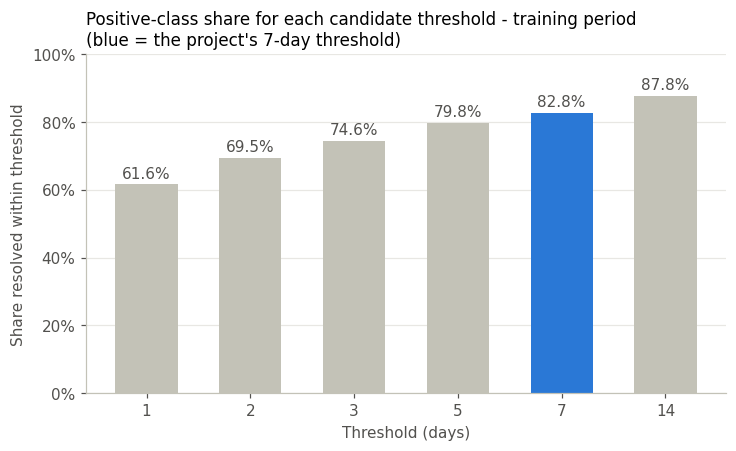

In [7]:
fig, ax = plt.subplots(figsize=(7.5, 4))
colors = [BLUE if d == THRESHOLD_DAYS else GREY for d in shares["threshold_days"]]
bars = ax.bar(shares["threshold_days"].astype(str), shares["resolved_within"], color=colors, width=0.6)
ax.bar_label(bars, labels=[f"{v:.1%}" for v in shares["resolved_within"]], color=INK, fontsize=10, padding=2)
ax.set_ylim(0, 1)
ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
ax.set_xlabel("Threshold (days)")
ax.set_ylabel("Share resolved within threshold")
ax.set_title("Positive-class share for each candidate threshold - training period\n(blue = the project's 7-day threshold)",
             loc="left", fontsize=11)
ax.grid(axis="x", visible=False)
fig.savefig(FIG_DIR / "01_positive_share_by_threshold.png")
plt.show()

## 1.5 Class balance for the 7-day target

Class 1 = resolved within 7 days. Class 0 = took longer than 7 days.

In [8]:
work["resolved_within_7d"] = (work["duration_hours"] <= THRESHOLD_DAYS * 24).astype(int)
train = work.iloc[:n_train]

balance = train["resolved_within_7d"].value_counts().sort_index().rename("rows").to_frame()
balance["share"] = balance["rows"] / balance["rows"].sum()
balance.index = ["0 = took longer than 7 days", "1 = resolved within 7 days"]
display(balance.style.format({"rows": "{:,}", "share": "{:.1%}"}))

smaller = balance["share"].min()
print(f"Smaller class share: {smaller:.1%}  ->  {'UNDER' if smaller < 0.20 else 'above'} the 20% rule")

,rows,share
0 = took longer than 7 days,"23,929",17.2%
1 = resolved within 7 days,"115,277",82.8%


Smaller class share: 17.2%  ->  UNDER the 20% rule


**Does the target change over time?** This chart uses *all* months (not only the training period), only to see whether recent months look different. It is a check, not something we tune on.

One thing to keep in mind when reading it: our sample contains **closed** requests only. In the most recent months, slow requests that are still open are missing, which can push the recent share up a little.

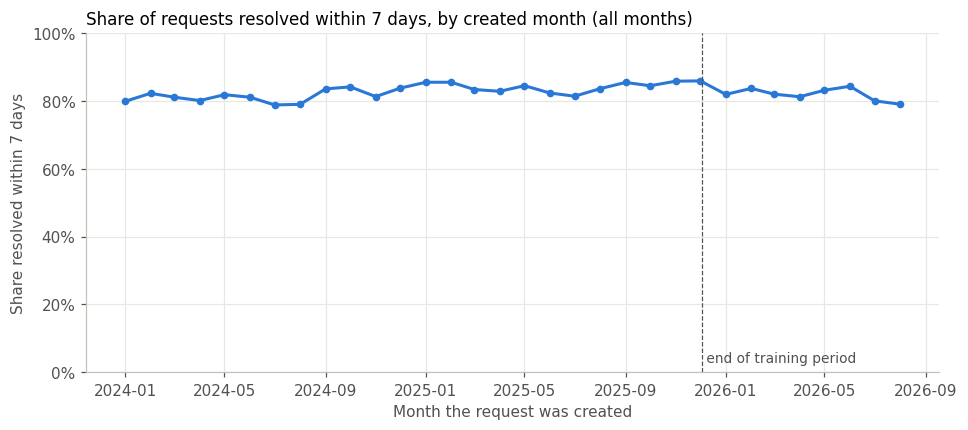

Training period : 82.8% resolved within 7 days
Later rows      : 82.4%
Lowest month    : 2024-07 at 78.9%
Highest month   : 2025-12 at 86.0%


In [9]:
by_month = work.groupby(work["created_date"].dt.to_period("M"))["resolved_within_7d"].agg(["mean", "size"])
by_month.index = by_month.index.to_timestamp()

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(by_month.index, by_month["mean"], color=BLUE, linewidth=2, marker="o", markersize=4)
ax.axvline(train_end, color=INK, linewidth=0.8, linestyle="--")
ax.text(train_end, 0.03, " end of training period", color=INK, fontsize=9)
ax.set_ylim(0, 1)
ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
ax.set_xlabel("Month the request was created")
ax.set_ylabel("Share resolved within 7 days")
ax.set_title("Share of requests resolved within 7 days, by created month (all months)", loc="left", fontsize=11)
fig.savefig(FIG_DIR / "01_positive_share_by_month.png")
plt.show()

print(f"Training period : {train['resolved_within_7d'].mean():.1%} resolved within 7 days")
print(f"Later rows      : {work.iloc[n_train:]['resolved_within_7d'].mean():.1%}")
print(f"Lowest month    : {by_month['mean'].idxmin():%Y-%m} at {by_month['mean'].min():.1%}")
print(f"Highest month   : {by_month['mean'].idxmax():%Y-%m} at {by_month['mean'].max():.1%}")

## 1.6 Which complaint types are fast and which are slow?

Share resolved within 7 days for each complaint type, training period only, and only for types with at least 500 training rows (smaller types give noisy percentages). A big gap between the fastest and slowest types means `complaint_type` should be a strong feature.

In [10]:
by_type = train.groupby("complaint_type")["resolved_within_7d"].agg(rows="size", share_within_7d="mean")
big = by_type[by_type["rows"] >= 500].sort_values("share_within_7d", ascending=False)
print(f"Complaint types in training period: {len(by_type)}; with at least 500 rows: {len(big)} "
      f"(covering {big['rows'].sum() / len(train):.1%} of training rows)")

fmt = {"rows": "{:,}", "share_within_7d": "{:.1%}"}
print("\n10 types with the HIGHEST share resolved within 7 days")
display(big.head(10).style.format(fmt))
print("10 types with the LOWEST share resolved within 7 days")
display(big.tail(10).sort_values("share_within_7d").style.format(fmt))

Complaint types in training period: 172; with at least 500 rows: 50 (covering 92.0% of training rows)

10 types with the HIGHEST share resolved within 7 days


,rows,share_within_7d
complaint_type,,
Abandoned Vehicle,"2,802",100.0%
Drug Activity,996,100.0%
Noise - Commercial,"2,650",100.0%
Non-Emergency Police Matter,991,100.0%
Panhandling,502,100.0%
Vendor Enforcement,"1,112",100.0%
Noise - Vehicle,"1,852",100.0%
Noise - Street/Sidewalk,"6,901",100.0%
Illegal Parking,"21,763",100.0%


10 types with the LOWEST share resolved within 7 days


,rows,share_within_7d
complaint_type,,
Food Establishment,507,0.4%
For Hire Vehicle Complaint,798,1.3%
Noise - Helicopter,718,1.9%
Building/Use,798,15.5%
Maintenance or Facility,976,31.6%
GENERAL,"1,261",31.6%
Elevator,849,31.6%
APPLIANCE,901,32.7%
Overgrown Tree/Branches,656,37.3%


## 1.7 Is the sample representative of the full table?

We kept about 1 request in 48. To check the sample is fair, we ask the Socrata API to count **all** closed requests in the same date range, grouped by borough and by complaint type, and compare the shares with our sample. (All raw sample rows are used here, because the API counts include every closed request.)

The API answers are saved in `data/raw/` so the notebook can be re-run without calling the API again.

In [11]:
import io
sys.path.append("../src")
from fetch_data import BASE_URL, END, START, get   # same helper used for the data pull

def full_table_counts(column):
    """Count ALL closed requests in the date range, grouped by one column."""
    cache = Path(f"../data/raw/full_closed_by_{column}.csv")
    if not cache.exists():
        params = {
            "$select": f"{column}, count(*) as n",
            "$where": f"status = 'Closed' AND created_date >= '{START}T00:00:00' AND created_date < '{END}T00:00:00'",
            "$group": column,
            "$order": "n DESC",
            "$limit": 5000,
        }
        cache.write_text(get(BASE_URL + ".csv", params), encoding="utf-8", newline="")
    return pd.read_csv(cache, dtype={column: str}, keep_default_na=False).set_index(column)["n"]

def compare(column):
    full = full_table_counts(column)
    sample = raw[column].fillna("").value_counts()
    out = pd.DataFrame({"full_rows": full, "sample_rows": sample}).fillna(0)
    out["full_share"] = out["full_rows"] / out["full_rows"].sum()
    out["sample_share"] = out["sample_rows"] / out["sample_rows"].sum()
    out["diff_pct_points"] = (out["sample_share"] - out["full_share"]) * 100
    return out.sort_values("full_rows", ascending=False)

share_fmt = {"full_rows": "{:,.0f}", "sample_rows": "{:,.0f}", "full_share": "{:.2%}",
             "sample_share": "{:.2%}", "diff_pct_points": "{:+.2f}"}

boroughs = compare("borough")
print(f"Full table closed rows: {boroughs['full_rows'].sum():,.0f}   sample rows: {boroughs['sample_rows'].sum():,.0f}")
print("\nBorough shares: full table vs sample")
display(boroughs.style.format(share_fmt))

Full table closed rows: 9,581,154   sample rows: 199,580

Borough shares: full table vs sample


,full_rows,sample_rows,full_share,sample_share,diff_pct_points
borough,,,,,
BROOKLYN,"2,894,302","60,050",30.21%,30.09%,-0.12
QUEENS,"2,310,448","48,164",24.11%,24.13%,+0.02
BRONX,"2,091,994","43,597",21.83%,21.84%,+0.01
MANHATTAN,"1,914,570","39,893",19.98%,19.99%,+0.01
STATEN ISLAND,"362,622","7,729",3.78%,3.87%,+0.09
Unspecified,"7,218",147,0.08%,0.07%,-0.00


In [12]:
types = compare("complaint_type")
print("Top 10 complaint types in the full table: full table vs sample")
display(types.head(10).style.format(share_fmt))

print("Largest differences across ALL complaint types (percentage points)")
largest = types.reindex(types["diff_pct_points"].abs().sort_values(ascending=False).index).head(5)
display(largest.style.format(share_fmt))

print(f"Largest borough difference       : {boroughs['diff_pct_points'].abs().max():.2f} percentage points")
print(f"Largest complaint-type difference: {types['diff_pct_points'].abs().max():.2f} percentage points")
print(f"Sample's top 10 types are the same as the full table's top 10: "
      f"{set(types.head(10).index) == set(types.sort_values('sample_rows', ascending=False).head(10).index)}")

Top 10 complaint types in the full table: full table vs sample


,full_rows,sample_rows,full_share,sample_share,diff_pct_points
complaint_type,,,,,
Illegal Parking,"1,498,254","31,272",15.64%,15.67%,+0.03
Noise - Residential,"1,092,670","22,790",11.40%,11.42%,+0.01
HEAT/HOT WATER,"774,994","16,139",8.09%,8.09%,-0.00
Blocked Driveway,"473,318","9,922",4.94%,4.97%,+0.03
Noise - Street/Sidewalk,"460,904","9,547",4.81%,4.78%,-0.03
UNSANITARY CONDITION,"327,318","6,787",3.42%,3.40%,-0.02
Street Condition,"227,347","4,743",2.37%,2.38%,+0.00
Water System,"196,873","4,107",2.05%,2.06%,+0.00
PLUMBING,"191,979","4,029",2.00%,2.02%,+0.02


Largest differences across ALL complaint types (percentage points)


,full_rows,sample_rows,full_share,sample_share,diff_pct_points
complaint_type,,,,,
ELECTRIC,"82,430","1,624",0.86%,0.81%,-0.05
Dirty Condition,"166,381","3,393",1.74%,1.70%,-0.04
Graffiti,"52,707","1,169",0.55%,0.59%,+0.04
Drug Activity,"57,692","1,139",0.60%,0.57%,-0.03
Illegal Parking,"1,498,254","31,272",15.64%,15.67%,+0.03


Largest borough difference       : 0.12 percentage points
Largest complaint-type difference: 0.05 percentage points
Sample's top 10 types are the same as the full table's top 10: True


## 1.8 Threshold recommendation

**What the numbers say (training period, 139,206 rows, 2024-01-01 to 2025-12-02):**

- With the 7-day threshold, **82.8%** of requests are class 1 (resolved within 7 days) and **17.2%** are class 0.
- The smaller class is **under the project's 20% guide**, by 2.8 percentage points. By the project rules this must be raised with the student, so the threshold is **not changed here**.
- Durations are very uneven: the median is only 7.0 hours, the 75th percentile is 3.08 days, but the mean is 11.9 days because a small number of requests stay open for months.
- The 7-day share is stable over time: every month is between 78.9% and 86.0%, and the later rows (82.4%) look like the training period (82.8%). So one threshold works for the whole date range.
- The sample matches the full table of 9,581,154 closed requests closely: the largest borough difference is 0.12 percentage points and the largest complaint-type difference is 0.05.

**Options:**

| Threshold | Class 1 | Class 0 (smaller) | Comment |
| --- | --- | --- | --- |
| 7 days (current) | 82.8% | 17.2% | Easy to explain ("within a week"); slightly under the 20% guide |
| 5 days | 79.8% | 20.2% | Closest threshold that passes the guide, but only just, and "5 days" is a less natural cut-off |
| 3 days | 74.6% | 25.4% | Clearly better balance; still easy to explain |
| Median (7.0 hours) | 50% | 50% | Perfect balance, but it changes the question to "is it closed the same day?" |

**Recommendation: keep 7 days.** The imbalance is mild (about 1 in 6 rows is the smaller class, which is 23,929 training rows, plenty to learn from). It can be handled without changing the question, by using `class_weight="balanced"` in the models and judging them with macro F1 and ROC-AUC instead of accuracy alone. A majority-class baseline would score 82.8% accuracy, so accuracy alone must not be used to claim success.

**If a better balance is preferred, the proposed alternative is 3 days** (25.4% in the smaller class). 5 days is the closest value that passes the 20% guide, but it passes by only 0.2 points.

**One more thing to know.** Complaint type almost decides the answer on its own: several large types (for example Illegal Parking and the noise types) are resolved within 7 days essentially 100% of the time, and a few (Food Establishment, For Hire Vehicle Complaint, Noise - Helicopter) almost never are. The models should score well, and most of the skill will come from `complaint_type`. This is true at any of the thresholds above.

**Decision needed from the student:** keep 7 days, or switch to 3 days (or another value).